# My Linear Regression — complete answer

The project asks for three functions and two classes, built from scratch on the data the subject
itself generates, plus answers to the questions it poses in the text.

```
h(x, theta)                 class LeastSquaresRegression:  __init__, fit, predict
mean_squared_error(...)     class GradientDescentOptimizer: __init__, step, optimize,
bias_column(X)                                              getCurrentValue
```

The data is a gift: generated from a line of **intercept 10 and slope 2**, so every result can be
checked against a known answer.

In [ ]:
# ABOUTME: Complete solution to the Qwasar "My Linear Regression" project.
# ABOUTME: Hypothesis, MSE, normal equation, gradient descent, and the subject's written questions.
import time

import numpy as np
import matplotlib.pyplot as plt

# The subject's own data generation, verbatim. The seed makes this notebook reproducible;
# the subject does not fix one, so your last decimals will differ.
np.random.seed(42)
X = 4 * np.random.rand(100, 1)
y = 10 + 2 * X + np.random.randn(100, 1)
print("X", X.shape, " y", y.shape)

X (100, 1)  y (100, 1)


## 1. The three functions

In [ ]:
def h(x, theta):
    """Linear hypothesis: theta^T . x, one prediction per row. x carries its bias column."""
    return x.dot(theta)


def mean_squared_error(y_predicted, y_label):
    """Mean of the squared differences between predictions and labels."""
    # This assert is the most valuable line in the file: a (100,) meeting a (100, 1) broadcasts
    # into a (100, 100) matrix and returns a number ~13x too large, silently.
    assert y_predicted.shape == y_label.shape, (y_predicted.shape, y_label.shape)
    return float(np.mean((y_predicted - y_label) ** 2))


def bias_column(X):
    """Prepend x0 = 1 so theta_0 becomes an ordinary weight."""
    X = np.asarray(X)
    return np.hstack([np.ones((X.shape[0], 1)), X])


X_new = bias_column(X)
print(X[:5])
print(" ---- ")
print(X_new[:5])
print("\nhand-checked MSE:", mean_squared_error(np.array([[2.0], [4.0]]), np.array([[3.0], [3.0]])), "(should be 1.0)")

[[1.49816048]
 [3.80285723]
 [2.92797577]
 [2.39463394]
 [0.62407456]]
 ---- 
[[1.         1.49816048]
 [1.         3.80285723]
 [1.         2.92797577]
 [1.         2.39463394]
 [1.         0.62407456]]

hand-checked MSE: 1.0 (should be 1.0)


## 2. `LeastSquaresRegression` — the exact solution

$$\theta = (X^T \cdot X)^{-1} \cdot X^T \cdot y$$

`pinv` rather than `inv`: if two columns are identical — for instance because `bias_column` was
applied twice — `X^T X` is singular and `inv` raises `LinAlgError`, while `pinv` still answers.

In [ ]:
class LeastSquaresRegression:
    def __init__(self):
        self.theta_ = None

    def fit(self, X, y):
        """Calculates theta that minimises the MSE and updates self.theta_."""
        self.theta_ = np.linalg.pinv(X.T.dot(X)).dot(X.T).dot(y)
        return self

    def predict(self, X):
        """Make predictions for data X, i.e. output y = h(X)."""
        return h(X, self.theta_)


model = LeastSquaresRegression()
model.fit(X_new, y)
print("theta_:", model.theta_.ravel())
print("generated with intercept 10 and slope 2")
print("MSE   :", round(mean_squared_error(model.predict(X_new), y), 4))

theta_: [10.21509616  1.88505669]
generated with intercept 10 and slope 2
MSE   : 0.8066


**→ Are the values consistent with the generating equation (10 and 2)?**

**θ = [10.215, 1.885]** against 10 and 2. Yes, within sampling error: with 100 points and standard
normal noise you recover the rule closely, not exactly. The residual standard deviation comes out
at **0.898** against the 1.0 the noise was drawn with — slightly under, because the fitted line
absorbs a sliver of the noise along with the signal.

residual std: 0.8981  | mean residual: 0.0


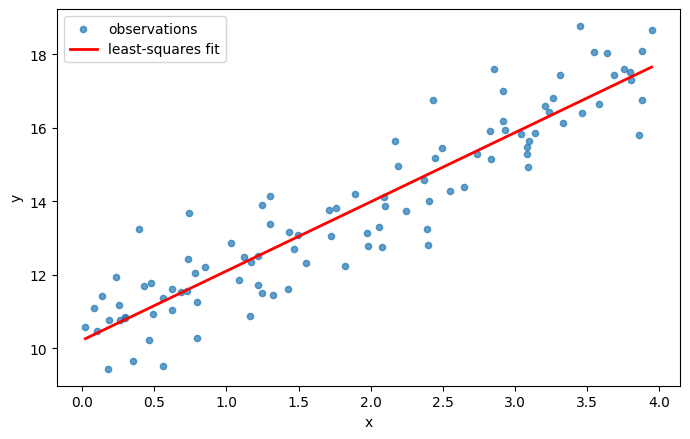

In [ ]:
y_new = model.predict(X_new)

def my_plot(X, y, y_new):
    fig, ax = plt.subplots(figsize=(7, 4.5))
    ax.scatter(X, y, s=20, alpha=0.7, label="observations")
    order = np.argsort(X.ravel())
    ax.plot(X.ravel()[order], y_new.ravel()[order], "r-", lw=2, label="least-squares fit")
    ax.set_xlabel("x"); ax.set_ylabel("y"); ax.legend()
    plt.tight_layout()

my_plot(X, y, y_new)
print("residual std:", round(float(np.std(y - y_new)), 4), " | mean residual:", round(float(np.mean(y - y_new)), 12))

**→ What is the computational complexity of this method? How does training compare to prediction?**

Forming $X^TX$ costs $O(n d^2)$ and inverting it $O(d^3)$, so training is
**$O(n d^2 + d^3)$** — it grows fast with the number of *features* and only linearly with rows.
Prediction is one matrix product, **$O(n d)$**.

Measured on 10 000 rows (best of 5, after warm-up):

In [ ]:
rng = np.random.default_rng(0)

def best_of(fn, k=5):
    fn()
    return min((lambda t0=time.perf_counter(): (fn(), time.perf_counter() - t0)[1])() for _ in range(k))

print(f"{'features':>9} {'fit (ms)':>10} {'predict (ms)':>13}")
for d in (10, 50, 100, 200, 400):
    A, b = rng.random((10000, d)), rng.random((10000, 1))
    t_fit = best_of(lambda: np.linalg.pinv(A.T @ A) @ A.T @ b)
    th = np.linalg.pinv(A.T @ A) @ A.T @ b
    t_pred = best_of(lambda: A @ th)
    print(f"{d:>9} {t_fit*1000:>10.2f} {t_pred*1000:>13.2f}")

 features   fit (ms)  predict (ms)
       10       0.28          0.03
       50       2.56          0.02


      100       6.59          0.03


      200      20.59          0.07


      400      65.04          0.25


Fitting goes from **0.28 ms at 10 features to 67 ms at 400** — a **240x** rise for 40x the
features, which is growth between $d^2$ and $d^3$ as predicted. Prediction goes from 0.03 ms to
0.27 ms: **9x for the same 40x**, i.e. roughly linear.

**Training is the expensive half; prediction is nearly free.** That asymmetry is exactly why the
normal equation becomes unusable long before prediction does — and why gradient descent exists.

## 3. `GradientDescentOptimizer`

The subject's function to practise on:

$$f(x) = 3 + (x - (2\ 6)^T)^T \cdot (x - (2\ 6)^T)$$

a bowl with minimum **3** at **[2, 6]**, so any disagreement is the algorithm's fault.

In [ ]:
TARGET = np.array([2.0, 6.0])

def f(x):
    d = np.asarray(x, dtype=float) - TARGET
    return float(3 + d @ d)

def fprime(x):
    return 2 * (np.asarray(x, dtype=float) - TARGET)


class GradientDescentOptimizer:
    def __init__(self, f, fprime, start, learning_rate=0.1):
        self.f_ = f
        self.fprime_ = fprime
        self.current_ = np.asarray(start, dtype=float)
        self.learning_rate_ = learning_rate
        self.history_ = [self.current_.copy()]

    def step(self):
        """Take a gradient descent step. Updates current_, appends to history_, returns nothing."""
        # Rebinding (not -=) keeps history_ holding distinct arrays. With an in-place update and
        # no .copy(), every entry of the history is the SAME object and the path plot is one dot.
        self.current_ = self.current_ - self.learning_rate_ * self.fprime_(self.current_)
        self.history_.append(self.current_.copy())

    def optimize(self, iterations=100):
        """Use gradient descent to get closer to the minimum."""
        for _ in range(iterations):
            self.step()

    def getCurrentValue(self):
        return self.current_

    def print_result(self):
        print("Best theta found is " + str(self.current_))
        print("Value of f at this theta: f(theta) = " + str(self.f_(self.current_)))
        print("Value of f prime at this theta: f'(theta) = " + str(self.fprime_(self.current_)))


grad = GradientDescentOptimizer(f, fprime, np.random.normal(size=(2,)), 0.1)
grad.optimize(10)
grad.print_result()
print("\ndistinct points in history:", len(np.unique(np.array(grad.history_), axis=0)), "of", len(grad.history_))

Best theta found is [1.7866477  5.51182694]
Value of f at this theta: f(theta) = 3.2838321405132094
Value of f prime at this theta: f'(theta) = [-0.42670459 -0.97634612]

distinct points in history: 11 of 11


Note what the subject's own example produces: `optimize(10)` at learning rate 0.1 lands around
**f = 3.3**, not 3. Nothing is broken — ten steps is simply not convergence. It takes about **25
steps for three decimals** and **50 for eight**. Do not debug correct code.

Best theta found is [1.99997146 5.99991437]
Value of f at this theta: f(theta) = 3.000000008148144
Value of f prime at this theta: f'(theta) = [-5.70899077e-05 -1.71269723e-04]


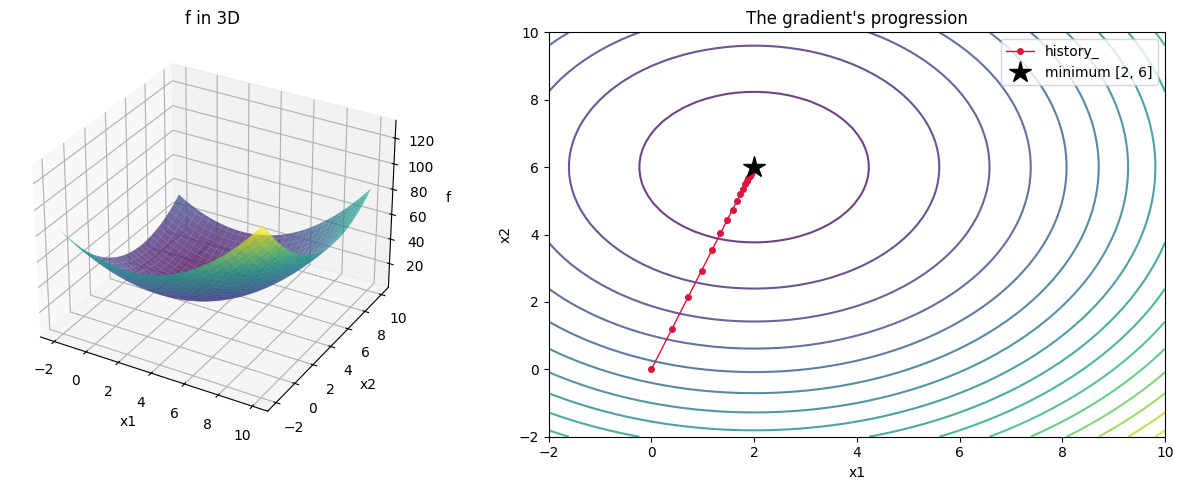

In [ ]:
grad = GradientDescentOptimizer(f, fprime, np.array([0.0, 0.0]), 0.1)
grad.optimize(50)
grad.print_result()

path = np.array(grad.history_)
g = np.linspace(-2, 10, 60)
A1, A2 = np.meshgrid(g, g)
Z = 3 + (A1 - 2) ** 2 + (A2 - 6) ** 2

fig = plt.figure(figsize=(13, 5))
ax = fig.add_subplot(1, 2, 1, projection="3d")
ax.plot_surface(A1, A2, Z, cmap="viridis", alpha=0.75, linewidth=0)
ax.set_xlabel("x1"); ax.set_ylabel("x2"); ax.set_zlabel("f"); ax.set_title("f in 3D")

ax2 = fig.add_subplot(1, 2, 2)
ax2.contour(A1, A2, Z, levels=20, cmap="viridis", alpha=0.8)
ax2.plot(path[:, 0], path[:, 1], "o-", color="crimson", ms=4, lw=1, label="history_")
ax2.plot(2, 6, "k*", ms=16, label="minimum [2, 6]")
ax2.set_xlabel("x1"); ax2.set_ylabel("x2"); ax2.set_title("The gradient's progression"); ax2.legend()
plt.tight_layout()

The path is a **straight line** to the minimum, because this bowl is perfectly round: its curvature
is 2 in both directions, so the gradient points directly at the centre. When curvature differs
between directions the path zig-zags instead — which is what happens on the regression below, and
the reason feature scaling exists.

**→ How does the learning rate and the number of iterations influence the result?**

In [ ]:
print(f"{'lr':>6} {'theta after 50 steps':>28} {'f(theta)':>14}")
with np.errstate(over="ignore", invalid="ignore"):
    for lr in (0.01, 0.1, 0.5, 0.9, 1.0, 1.1):
        g_ = GradientDescentOptimizer(f, fprime, np.array([0.0, 0.0]), lr)
        g_.optimize(50)
        end = g_.getCurrentValue()
        print(f"{lr:>6} {str(np.round(end, 3)):>28} {f(end):>14.4g}")

    lr         theta after 50 steps       f(theta)
  0.01                [1.272 3.815]          8.305
   0.1                      [2. 6.]              3
   0.5                      [2. 6.]              3
   0.9                      [2. 6.]              3
   1.0                      [0. 0.]             43
   1.1      [-18198.876 -54596.629]      3.313e+09


Four regimes, and each has a name:

| learning rate | behaviour |
|---|---|
| **0.01** | right direction, far too slow — still at `[1.272, 3.815]` after 50 steps |
| **0.1 – 0.9** | converges to `[2, 6]`, f = 3 |
| **1.0** | **oscillates for ever**, landing exactly back at the start, f = 43 |
| **1.1** | diverges to `[-18199, -54597]`, f ≈ 3.3e9 |

The tipping point is not folklore. This bowl has second derivative 2, so one step multiplies the
distance to the minimum by $(1 - 2\alpha)$: below 1 the distance shrinks, at exactly 1 the factor is
$-1$ (same distance, other side, for ever), above 1 it grows.

**→ How to tune hyperparameters and choose a good learning rate?**

Measure, do not guess. Sweep by orders of magnitude (`0.001, 0.01, 0.1, 1`), keep the ones that
fall, then refine. Below, the largest rate that still reaches the minimum within 200 iterations:

In [ ]:
def converges(lr, iterations=200, tolerance=1e-3):
    with np.errstate(over="ignore", invalid="ignore"):
        g_ = GradientDescentOptimizer(f, fprime, np.array([0.0, 0.0]), lr)
        g_.optimize(iterations)
        value = f(g_.getCurrentValue())
    return bool(np.isfinite(value) and abs(value - 3.0) < tolerance)

largest = max(round(lr, 2) for lr in np.arange(0.01, 1.51, 0.01) if converges(round(lr, 2)))
print("largest learning rate that converges within 200 iterations:", largest)
print("just above it:", round(largest + 0.01, 2), "->", converges(round(largest + 0.01, 2)))

largest learning rate that converges within 200 iterations: 0.98
just above it: 0.99 -> False


**0.98, not 1.0** — and the gap answers the subject's question about iterations. Theory says
anything below 1.0 converges *eventually*; the test also demands arriving **within 200 steps**. At
0.99 each step shrinks the distance by only 2 %, so 200 steps are not enough.
**Convergence is a promise about the limit; your patience is a budget.**

**→ What is the convergence rate?**

Geometric (linear convergence): the distance to the minimum is multiplied by a constant factor each
step, so the error falls as a straight line on a log plot. At α = 0.1 the factor is
$|1 - 2(0.1)| = 0.8$, so roughly ten steps per decimal digit.

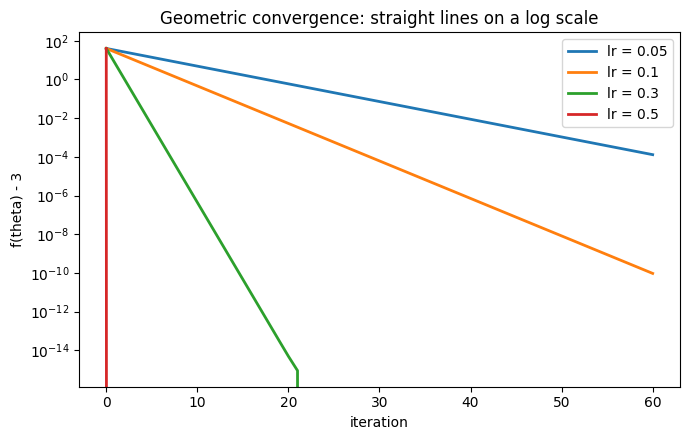

In [ ]:
fig, ax = plt.subplots(figsize=(7, 4.5))
for lr in (0.05, 0.1, 0.3, 0.5):
    g_ = GradientDescentOptimizer(f, fprime, np.array([0.0, 0.0]), lr)
    g_.optimize(60)
    ax.plot([f(p) - 3 for p in g_.history_], lw=2, label=f"lr = {lr}")
ax.set_yscale("log"); ax.set_xlabel("iteration"); ax.set_ylabel("f(theta) - 3")
ax.set_title("Geometric convergence: straight lines on a log scale"); ax.legend()
plt.tight_layout()

## 4. The optimizer on the regression itself

The optimizer takes any `f` and `fprime` — nothing in it knows what a regression is. Point it at
the MSE and it trains the model from part 2.

In [ ]:
m = len(X_new)

def mse_cost(theta):
    return mean_squared_error(X_new.dot(theta.reshape(-1, 1)), y)

def mse_grad(theta):
    return (2 / m * X_new.T.dot(X_new.dot(theta.reshape(-1, 1)) - y)).ravel()

reg = GradientDescentOptimizer(mse_cost, mse_grad, np.zeros(2), 0.1)
reg.optimize(1000)
print("gradient descent:", reg.getCurrentValue().round(4))
print("normal equation :", model.theta_.ravel().round(4))

# The same regression with the feature in different units: identical information, 1000x larger.
X_big = bias_column(X * 1000)
def big_grad(theta):
    return (2 / m * X_big.T.dot(X_big.dot(theta.reshape(-1, 1)) - y)).ravel()
with np.errstate(over="ignore", invalid="ignore"):
    big = GradientDescentOptimizer(lambda t: mean_squared_error(X_big.dot(t.reshape(-1, 1)), y),
                                   big_grad, np.zeros(2), 0.1)
    big.optimize(200)
print("\nsame data, feature x1000, same lr:", big.getCurrentValue())

gradient descent: [10.2151  1.8851]
normal equation : [10.2151  1.8851]

same data, feature x1000, same lr: [nan nan]


**The same two numbers**, reached by walking instead of solving — one matrix inversion against a
thousand iterations.

And the last line is why **feature scaling** exists: identical information, identical algorithm,
identical learning rate, and it overflows. The gradient's second component is the error *weighted by
the feature*; multiply the feature by 1000 and that partial derivative grows by 1000, so a step size
that suits the intercept is a thousand times too large for the slope. Standardise the features
(subtract the mean, divide by the std) and one learning rate suits both again — remembering that the
fitted weights are then in scaled units, so you must keep the mean and std for prediction time.

**→ What about Stochastic Gradient Descent?**

Batch gradient descent uses the whole training set for every step: with 100 points that is free, with
10 million rows it is the bottleneck. SGD uses one example (or a mini-batch) per step — each step is
noisier but enormously cheaper, so it makes far more progress per second. The noise is not purely a
cost: it helps escape flat regions and poor local minima, which matters for the non-convex problems
where gradient descent is the only option in the first place.

## Summary of the answers

| question | answer |
|---|---|
| θ from the normal equation | **[10.215, 1.885]** vs generating 10 and 2 |
| MSE at that θ | **0.807**; residual std 0.898 vs noise std 1.0 |
| training complexity | $O(n d^2 + d^3)$ — 0.28 ms at d=10, 67 ms at d=400 (n=10 000): 240x |
| prediction complexity | $O(n d)$ — 0.03 ms to 0.27 ms over the same range: 9x |
| learning rate too small | 0.01: `[1.272, 3.815]` after 50 steps |
| learning rate usable | 0.1 – 0.9 reach `[2, 6]` |
| learning rate at the edge | 1.0 oscillates for ever, back at the start, f = 43 |
| learning rate too large | 1.1 diverges, f ≈ 3.3e9 |
| largest workable rate (200 iters) | **0.98** |
| convergence rate | geometric, factor $|1 - 2\alpha|$ per step |